# Training on one TS, fixing alpha and testing on the rest using pseudo-scores

In [1]:
from astropy.io import fits

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy import stats as ss
from scipy.io import readsav
from sklearn.decomposition import PCA

from tqdm import tqdm
from IPython.display import display, Latex

import tools as t

## Load data

In [ ]:
# load files
path_data = '../data/sim_series/'  # directory where the files are saved
N_files = 20  # 20 time series (from 0 to 19)
data_spectra = []
data_rv = []

for i in range(N_files):  # files have the same name, only number changes
    data_spectra.append(fits.getdata(path_data + f'flux_norm_6173_lionel_tau1_spatialscaling1_sansrotation_serie{i}.fits'))
    data_rv.append(readsav(path_data + f'res_rv_bis_6173_lionel_tau1_scaling1_sansrot_serie{i}.sav'))
    
data_spectra = np.array(data_spectra)
data_rv = np.array(data_rv)
print(data_rv[0].keys())

dict_keys(['rv_gauss', 'rv_correl', 'rv_deriv', 'xbiss', 'ybiss', 'l_true', 'lambd', 'flux_moy'])


In [ ]:
c = 3e8  # speed of light [m/s]
# extract data
wl = np.array(data_rv[0]['lambd'])  # same wavelength grid for all time series
times = np.arange(0, len(data_spectra[0]) * 144, 144) / 60 / 24  # time in days, same for all time series
times_sec = times * 86400  # time in sec
# extract wavelength data
wl = np.array(wl)

## Work with only one TS

In [4]:
# selecting TS
ts_index = 0
spectra_ex = data_spectra[ts_index]

# splitting the selected TS in two halves
N = len(times)
N_half = N // 2

times_half = times[:N_half]

spectra_0 = spectra_ex[:N_half]  # first half, 70% for training and 30% for testing
spectra_1 = spectra_ex[N_half:]  # second half, for testing

## Preprocessing

In [5]:
# calculating the mean spectra
mean_spec_0 = np.mean(spectra_0, axis=0)
mean_spec_1 = np.mean(spectra_1, axis=0)

# derivatives of the mean spectra
d_S0 = np.gradient(mean_spec_0, wl)
d_S1 = np.gradient(mean_spec_1, wl)

In [6]:
# subtracting Doppler vector
Sf_0, D_0 = t.subtract_D(wl, spectra_0, c=c)  # S_f and Doppler vector
Sf_1, D_1 = t.subtract_D(wl, spectra_1, c=c)

# double centering
spectra_centered_0 = t.double_centering(Sf_0)
spectra_centered_1 = t.double_centering(Sf_1)

In [7]:
# preprocessing all TS
mean_spec = np.array([np.mean(i, axis=0) for i in data_spectra])  # list of mean spectrum for each TS
d_S0 = np.array([np.gradient(i, wl) for i in mean_spec])          # list of derivative of the mean spectrum for each TS

S_f = []        # array of matrices
D_vectors = []  # array of Doppler vectors

for i in range(N_files):  # iterate over TS
    s, v = t.subtract_D(wl, data_spectra[i], c=c)  # returns S_f and Doppler vector
    S_f.append(s)
    D_vectors.append(v)

S_f = np.array(S_f)
D_vectors = np.array(D_vectors)

# double centering
spectra_centered = np.array([t.double_centering(i) for i in S_f])

## Calculate RV by template matching

In [8]:
# calculating radial velocity by template matching
C_0 = 1000  # continuum constant

# list of RVs for each timestep
rv_0 = np.array([
    t.calculate_rv(wl, mean_spec_0, spectra_0[i], C_0) for i in range(N_half)
    ])

rv_1 = np.array([
    t.calculate_rv(wl, mean_spec_1, spectra_1[i], C_0) for i in range(N_half)
    ])

In [9]:
# calculating RV for all the TS
rv_tm = []  # list of RV vector for each TS
for j in range(N_files):  # iterate over TS
    rv_j = []
    for k in range(len(times)):  # iterate over spectra
        rv_j.append(t.calculate_rv(wl, mean_spec[j], data_spectra[j][k], C_0))  # calculate RV by TM
    rv_tm.append(np.array(rv_j))
rv_tm = np.array(rv_tm)

## PCA

In [10]:
# applying PCA to the centered matrix
n_components = 16

# first half
pca_flux_0 = PCA(n_components=n_components)           # create PCA object
pcs_0 = pca_flux_0.fit_transform(spectra_centered_0)  # fit the model with spectra_centered and apply the dimensionality reduction
loadings_0 = pca_flux_0.components_                   # save loadings
scores_0 = pcs_0                                      # save scores
var_0 = pca_flux_0.explained_variance_ratio_          # save PC variation

# second half
pca_flux_1 = PCA(n_components=n_components)           # create PCA object
pcs_1 = pca_flux_1.fit_transform(spectra_centered_1)  # fit the model with spectra_centered and apply the dimensionality reduction
loadings_1 = pca_flux_1.components_                   # save loadings
scores_1 = pcs_1                                      # save scores
var_1 = pca_flux_1.explained_variance_ratio_          # save PC variation

In [11]:
# checking shapes
print(f'Centred TS of spectra shape: {spectra_centered_0.shape}')
print(f'Loadings shape: {loadings_0.shape}')
print(f'Scores shape: {scores_0.shape}')

Centred TS of spectra shape: (1843, 122)
Loadings shape: (16, 122)
Scores shape: (1843, 16)


In [12]:
# checking if the projection of spectra_centered over the loadings (pseudo-scores) is equal to the scores
pseudo_scores_0 = []
for i in range(n_components):
    pseudo_scores_i = []
    loadings_i = loadings_0[i]
    for j in range(N_half):
        pseudo_scores_ij = np.dot(loadings_i.T, spectra_centered_0[j]) / np.linalg.norm(loadings_i)**2
        pseudo_scores_i.append(pseudo_scores_ij)
    pseudo_scores_0.append(pseudo_scores_i)
pseudo_scores_0 = np.array(pseudo_scores_0).T

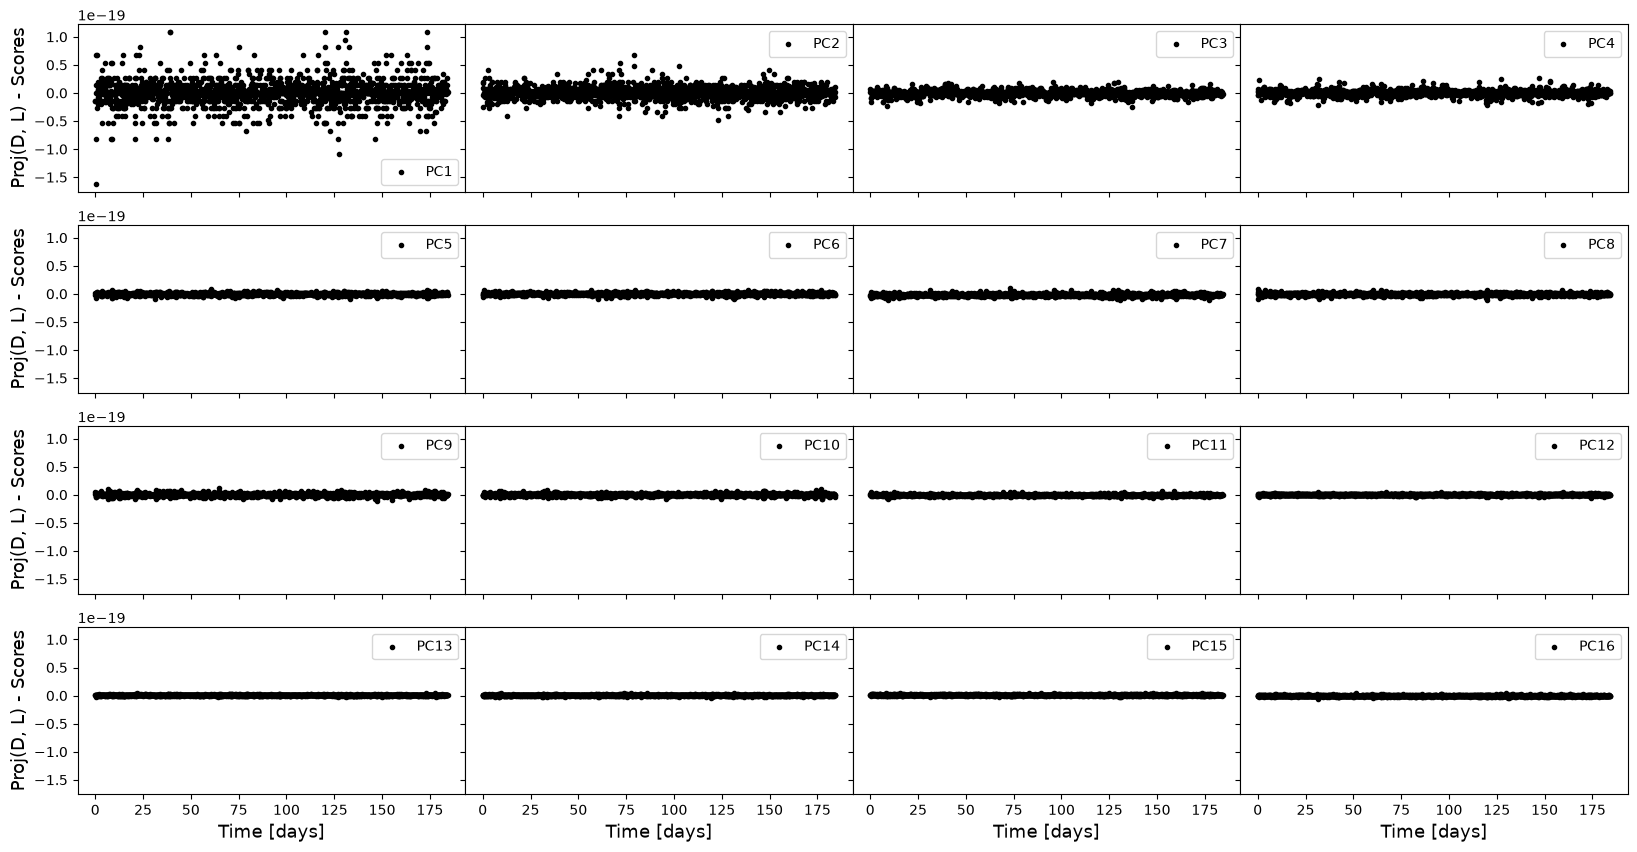

In [13]:
# plot difference between scores and pseudo-scores for each PC
rows = 4
cols = 4
fig, axs = plt.subplots(rows, cols, figsize=(20, 10), sharex=True, sharey=True)

pc = 0  # PC counter
for row in range(rows):
    for col in range(cols):
        axs[row][col].scatter(times_half, pseudo_scores_0[:, pc] - scores_0[:, pc], color='k', marker='.', label=f'PC{pc + 1}')
        if row == rows - 1:
            axs[row][col].set_xlabel('Time [days]', size=13)
        if col == 0:
            axs[row][col].set_ylabel('Proj(D, L) - Scores', size=13)
        axs[row][col].legend()
        pc += 1

plt.subplots_adjust(wspace=0)
plt.show()

In [14]:
# smallest score values vs maximum difference
for i in range(n_components):
    print(f'PC {i+1}: Minimum score: {min(np.abs(scores_0[:, i])):.2e}; Maximum difference with pseudo-scores: {max(pseudo_scores_0[:, i] - scores_0[:, i]):.2e}.')

PC 1: Minimum score: 8.39e-08; Maximum difference with pseudo-scores: 1.08e-19.
PC 2: Minimum score: 9.16e-09; Maximum difference with pseudo-scores: 6.78e-20.
PC 3: Minimum score: 2.37e-09; Maximum difference with pseudo-scores: 2.03e-20.
PC 4: Minimum score: 8.59e-10; Maximum difference with pseudo-scores: 2.71e-20.
PC 5: Minimum score: 1.58e-10; Maximum difference with pseudo-scores: 8.68e-21.
PC 6: Minimum score: 4.46e-10; Maximum difference with pseudo-scores: 6.56e-21.
PC 7: Minimum score: 8.11e-11; Maximum difference with pseudo-scores: 1.12e-20.
PC 8: Minimum score: 2.55e-11; Maximum difference with pseudo-scores: 8.84e-21.
PC 9: Minimum score: 1.11e-10; Maximum difference with pseudo-scores: 1.28e-20.
PC 10: Minimum score: 1.10e-10; Maximum difference with pseudo-scores: 1.08e-20.
PC 11: Minimum score: 9.68e-11; Maximum difference with pseudo-scores: 6.58e-21.
PC 12: Minimum score: 1.03e-10; Maximum difference with pseudo-scores: 5.55e-21.
PC 13: Minimum score: 5.74e-12; Maxim

The difference between the scores and the pseudo-scores is several orders of magnitude below the values of the scores.

## Linear Model

In [15]:
# train/test split
train_size = int(.7 * N_half)
# I_train_0  = scores_0[:train_size]      # matrix with scores as columns
I_train_0 = pseudo_scores_0[:train_size]  # matrix with pseudo-scores as columns
rv_true_train_0 = rv_0[:train_size]       # true RVs of the sample
times_train = times_half[:train_size]     # corresponding time grid

#I_test_0  = scores_0[train_size:]       # matrix with scores as columns
I_test_0 = pseudo_scores_0[train_size:]  # matrix with pseudo-scores as columns
rv_true_test_0 = rv_0[train_size:]       # true RVs of the sample
times_test = times_half[train_size:]     # corresponding time grid

# training the model
G = np.dot(I_train_0.T, I_train_0)
b = np.dot(I_train_0.T, rv_true_train_0)
alpha = np.linalg.solve(G, b)  # will stay fixed for all of the tests

In [16]:
# showing the values of alpha
for i in range(n_components):
    display(Latex(rf'$\alpha_{{{i + 1}}} = {alpha[i]:.1e}$'))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

...

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [17]:
# checking dot(G, alpha) = b
np.allclose(np.dot(G, alpha), b)

True

In [18]:
# testing on the test sample of the same half

chunk_size = 21   # using chunks to get error bars

rv_pred_test_0 = []    # list of chunks of predicted RV
res_test_0 = []        # list of chunks of residuals calculated from rv_pred
res_sigma_test_0 = []  # list of std of the residuals in each chunk

j = 0
while j < len(rv_true_test_0):  # iterate over chunks
    if j + chunk_size > len(rv_true_test_0):  # last elements of the TS not included if (N % chunk_size != 0)
        break

    else:
        pseudo_scores_j = I_test_0[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
        rv_true_j = rv_true_test_0[j:j+chunk_size]  # chunk_size values of RV
        
        rv_pred_j = np.dot(pseudo_scores_j, alpha)  # predict chunk_size values of RV
        res_j = rv_true_j - rv_pred_j               # residuals in the chunk

        rv_pred_test_0.append(rv_pred_j)        # save chunk of resulting RV
        res_test_0.append(res_j)                # save residuals in the chunk
        res_sigma_test_0.append(np.std(res_j))  # save std of the residuals in the chunk

    j += chunk_size

rv_pred_test_0 = np.array(rv_pred_test_0)
res_test_0 = np.array(res_test_0)
res_test_0_flat = res_test_0.flatten()  # 1-d version of the residuals to ease plotting
res_sigma_test_0 = np.array(res_sigma_test_0)

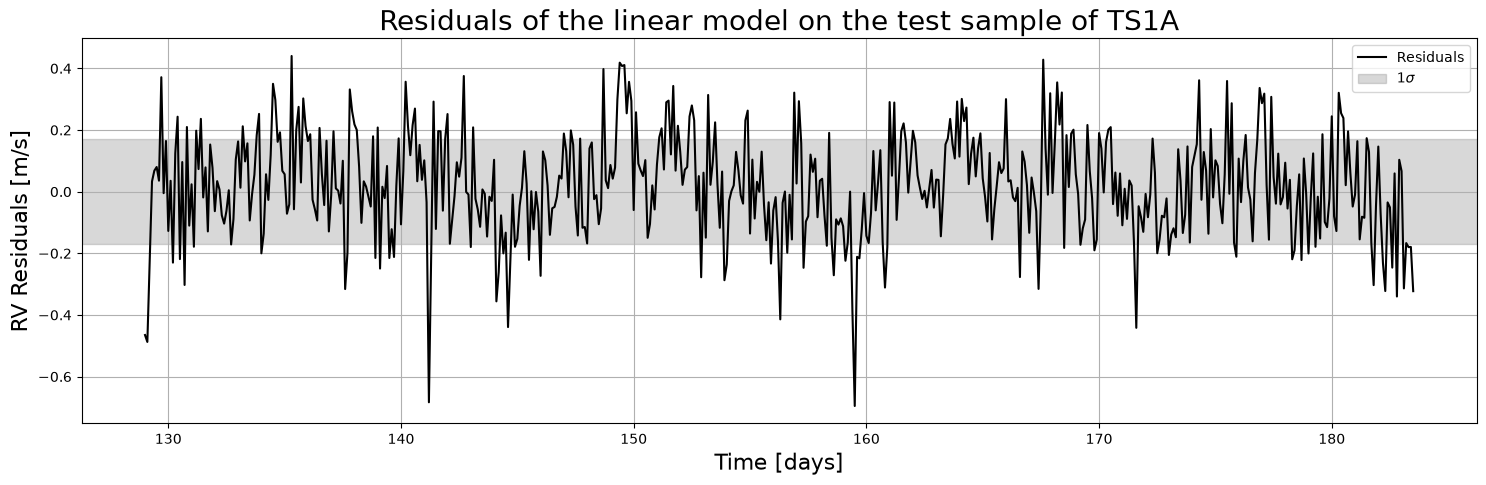

In [19]:
# showing the residuals
fig, ax = plt.subplots(figsize=(18, 5))
ax.set_title(f'Residuals of the linear model on the test sample of TS{ts_index + 1}A', size=20)

ax.grid()
ax.plot(times_test[:len(res_test_0_flat)], res_test_0_flat, color='k', label='Residuals')
ax.axhspan(-np.std(res_test_0), np.std(res_test_0), color='gray', alpha=.3, label=r'$1\sigma$')

ax.set_xlabel('Time [days]', size=16)
ax.set_ylabel('RV Residuals [m/s]', size=16)
ax.legend()

plt.show()

In [20]:
print(f'The standard deviation of the residuals is {np.std(res_test_0):.3f} m/s.')  # using pseudo-scores gives the same result as using scores (only for TSXA!)

The standard deviation of the residuals is 0.170 m/s.


In [21]:
# calculating pseudo-scores for the second half
pseudo_scores_1 = []
for i in range(n_components):
    pseudo_scores_i = []
    loadings_i = loadings_0[i]  # using loadings from the first half
    for j in range(N_half):
        pseudo_scores_ij = np.dot(loadings_i.T, spectra_centered_1[j]) / np.linalg.norm(loadings_i)**2  # projecting spectra from the second half on the loadings from the first half
        pseudo_scores_i.append(pseudo_scores_ij)
    pseudo_scores_1.append(pseudo_scores_i)
pseudo_scores_1 = np.array(pseudo_scores_1).T

# testing on the whole second half
rv_pred_1 = []    # list of chunks of predicted RV
res_1 = []        # list of chunks of residuals calculated from rv_pred
res_sigma_1 = []  # list of numbers: std of each chunk in res

j = 0
while j < N_half:  # iterate over chunks
    if j + chunk_size > N_half:  # leaving out the last elements of the TS if chunk_size is not a factor of N
        break

    else:
        pseudo_scores_j = pseudo_scores_1[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
        rv_true_j = rv_1[j:j+chunk_size]  # chunk_size values of RV

        rv_pred_j = np.dot(pseudo_scores_j, alpha)  # predict chunk_size values of RV
        res_j = rv_true_j - rv_pred_j  # chunk residuals

        rv_pred_1.append(rv_pred_j)        # save chunk of resulting RV
        res_1.append(res_j)                # save residuals in the chunk
        res_sigma_1.append(np.std(res_j))  # save std of the residuals in the chunk
    j += chunk_size

rv_pred_1 = np.array(rv_pred_1)
res_1 = np.array(res_1)
res_1_flat = res_1.flatten()  # 1-d version of the residuals to ease plotting
res_sigma_1 = np.array(res_sigma_1)

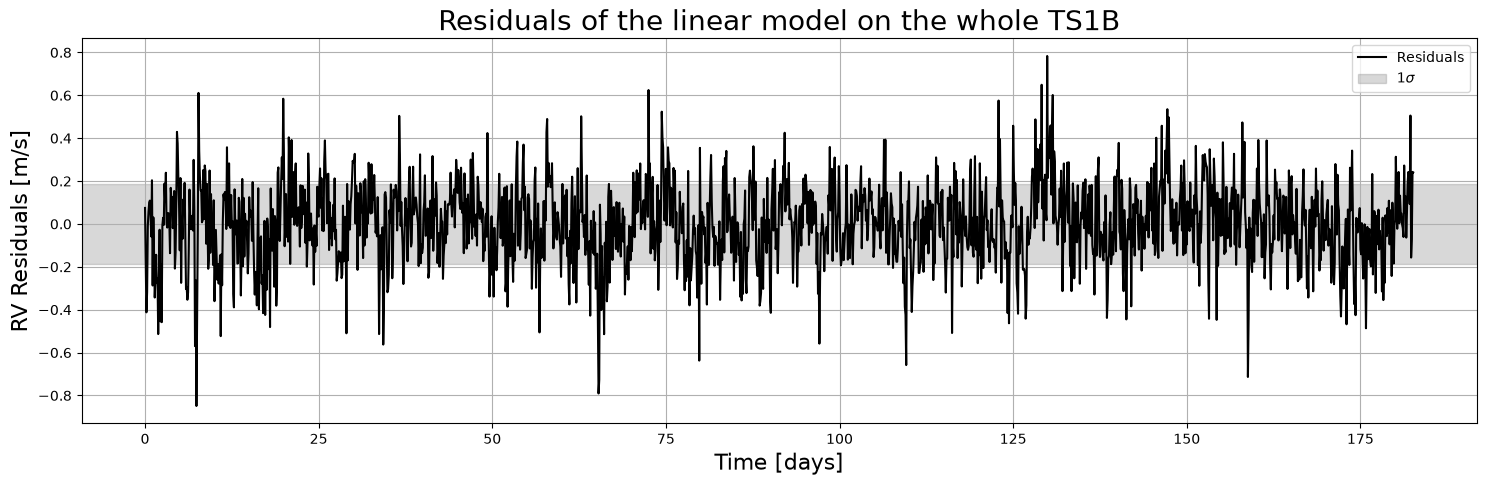

In [22]:
# showing the residuals of the predictions over the whole TSXB
fig, ax = plt.subplots(figsize=(18, 5))
ax.set_title(f'Residuals of the linear model on the whole TS{ts_index + 1}B', size=20)

ax.grid()
ax.plot(times_half[:len(res_1_flat)], res_1_flat, color='k', label='Residuals')
ax.axhspan(-np.std(res_1), np.std(res_1), color='gray', alpha=.3, label=r'$1\sigma$')

ax.set_xlabel('Time [days]', size=16)
ax.set_ylabel('RV Residuals [m/s]', size=16)
ax.legend()

plt.show()

In [23]:
print(f'The standard deviation of the residuals is {np.std(res_1):.3f} m/s.')  # in this case, using pseudo-scores gives a much better result than using scores

The standard deviation of the residuals is 0.188 m/s.


## Testing on all other TS

In [24]:
# creating pseudo-scores for each TS, using spectra_centered and the reference loadings (loadings_0)
pseudo_scores = []

for k in range(N_files):  # iterate over TS
    spectra_centered_k = spectra_centered[k]
    pseudo_scores_k = []  # pseudo-scores of the k-th TS
    for i in range(n_components):  # iterate over PCs
        pseudo_scores_i = []  # pseudo-scores of the i-th PC
        loadings_i = loadings_0[i]  # using reference loadings
        for j in range(N):  # iterate over timesteps
            pseudo_scores_ij = np.dot(loadings_i.T, spectra_centered_k[j]) / np.linalg.norm(loadings_i)**2  # pseudo-score of the j-th timestep, of the i-th PC, of the k-th TS
            pseudo_scores_i.append(pseudo_scores_ij)
        pseudo_scores_k.append(pseudo_scores_i)
    pseudo_scores.append(np.array(pseudo_scores_k).T)

pseudo_scores = np.array(pseudo_scores)

In [25]:
# checking shape
print(pseudo_scores.shape)

(20, 3686, 16)


In [ ]:
# testing with chunks

rv_pred = []    # array: each element is a list of chunks of predicted RV
res = []        # array: each element is a list of residuals (chunked)
res_sigma = []  # array: each element is a list if the std of the residuals in each chunk

for i in range(N_files):  # iterate over TS

    pseudo_scores_i = pseudo_scores[i]
    rv_true_i = rv_tm[i]

    rv_pred_i = []    # list of chunks of predicted RV
    res_i = []        # list of chunks of residuals calculated from rv_pred_i
    res_sigma_i = []  # list of numbers: std of each chunk in res_i

    j = 0

    while j < N:  # iterate over chunks

        if j + chunk_size > N:  # leaving out the last elements of the TS if chunk_size is not a factor of N
            break

        else:
            pseudo_scores_j = pseudo_scores_i[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
            rv_true_j = rv_true_i[j:j+chunk_size]  # chunk_size values of RV

            rv_pred_j = np.dot(pseudo_scores_j, alpha)  # predict chunk_size values of RV
            res_j = rv_true_j - rv_pred_j  # chunk residuals
            
            rv_pred_i.append(rv_pred_j)        # save chunk of resulting RV
            res_i.append(res_j)                # save residuals in the chunk
            res_sigma_i.append(np.std(res_j))  # save std of the residuals in the chunk
        
        j += chunk_size

    rv_pred.append(np.array(rv_pred_i))
    res.append(np.array(res_i))
    res_sigma.append(np.array(res_sigma_i))

rv_pred = np.array(rv_pred)
res = np.array(res)
res_sigma = np.array(res_sigma)

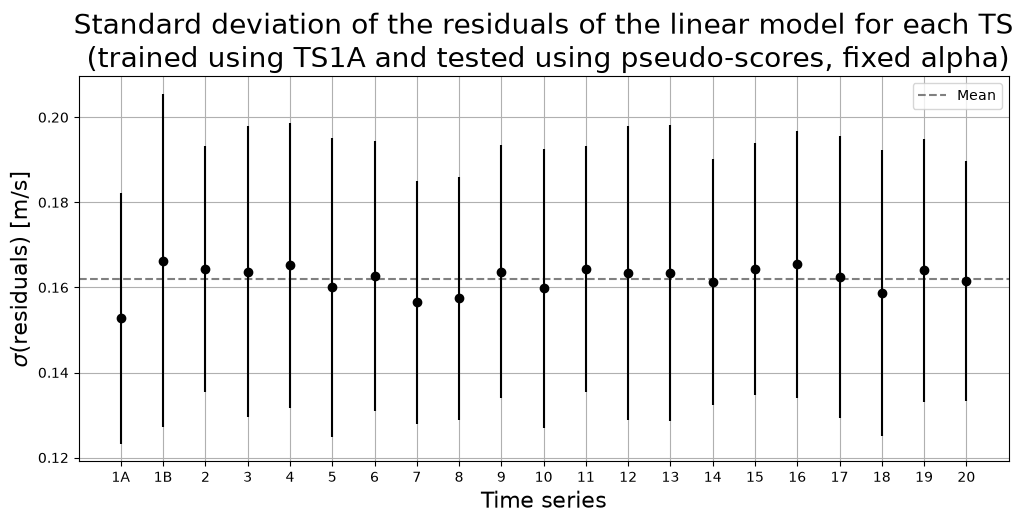

In [27]:
# showing std for each TS
ts_arr = np.linspace(1, N_files + 1, N_files + 1)  # array of integers from 1 to the number of TS (+1 to account for splitting the reference TS)

# array of the results for each TS
y = np.mean(res_sigma, axis=1)
y_err = np.std(res_sigma, axis=1)

y = np.delete(y, ts_index)  # taking out reference TS
y_err = np.delete(y_err, ts_index)

y = np.insert(y, ts_index, np.mean(res_sigma_1))  # inserting TSXB results
y_err = np.insert(y_err, ts_index, np.std(res_sigma_1))

y = np.insert(y, ts_index, np.mean(res_sigma_test_0))  # inserting TSXA results
y_err = np.insert(y_err, ts_index, np.std(res_sigma_test_0))

# create a list for xticklabels
xticklabels = []
for i in range(1, N_files + 1):
    if i == ts_index + 1:
        xticklabels.append(f"{i}A")
        xticklabels.append(f"{i}B")
    else:
        xticklabels.append(str(i))

# plot
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title(f'Standard deviation of the residuals of the linear model for each TS\n (trained using TS{ts_index+1}A and tested using pseudo-scores, fixed alpha)', size=20)

ax.grid()
ax.errorbar(ts_arr, y, y_err, fmt='o', color='k', zorder=2)
ax.axhline(np.mean(y), color='gray', linestyle='--', label='Mean', zorder=1)

ax.set_xlabel('Time series', size=16)
ax.set_ylabel(r'$\sigma$(residuals) [m/s]', size=16)

ax.set_xticks(ts_arr)
ax.set_xticklabels(xticklabels)

ax.legend()
plt.show()

In [28]:
# overall sigma_res
print(f'The mean of Sigma(res) over all TS is {np.mean(y):.3f} +- {np.std(y):.3f} m/s.')
print(f'The mean of the error bars is {np.mean(y_err):.3f} m/s.')

The mean of Sigma(res) over all TS is 0.162 +- 0.003 m/s.
The mean of the error bars is 0.032 m/s.


In [29]:
# mean and standard deviation of the residuals (per chunk) for TSXA
print(f'TS{ts_index + 1}A: Sigma(res) = {np.mean(res_sigma_test_0):.3f} +- {np.std(res_sigma_test_0):.3f} m/s.')

# mean and standard deviation of the residuals (per chunk) for TSXB
print(f'TS{ts_index + 1}B: Sigma(res) = {np.mean(res_sigma_1):.3f} +- {np.std(res_sigma_1):.3f} m/s.')

TS1A: Sigma(res) = 0.153 +- 0.030 m/s.
TS1B: Sigma(res) = 0.166 +- 0.039 m/s.


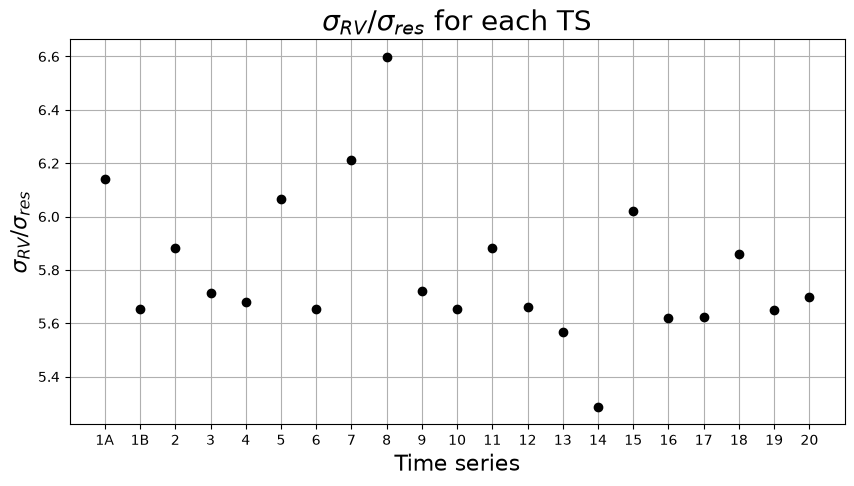

In [30]:
# showing sigma(RV) / sigma(residuals)
sigma_rv = np.std(rv_tm, axis=1)  # standard deviation of the RVs of each TS
sigma_ratio = sigma_rv / np.mean(res_sigma, axis=1)

y = np.delete(sigma_ratio, ts_index)  # take out TSX

# insert TSXB and TSXA
y = np.insert(y, ts_index, np.std(rv_1[:len(res_1.flatten())]) / np.mean(res_sigma_1))  # the RV arrays are cut to take out the points that were left out while chunking
y = np.insert(y, ts_index, np.std(rv_true_test_0[:len(res_test_0.flatten())]) / np.mean(res_sigma_test_0))

fig, ax = plt.subplots(figsize=(10, 5))

ax.set_title(r'$\sigma_{RV} / \sigma_{res}$ for each TS', size=20)

ax.grid()
ax.scatter(ts_arr, y, color='k', zorder=2)

ax.set_xlabel('Time series', size=16)
ax.set_ylabel(r'$\sigma_{RV} / \sigma_{res}$', size=16)
ax.set_xticks(ts_arr)
ax.set_xticklabels(xticklabels)

plt.show()